# UMAP Figures

Final figures for step 3 (see `README.md`): the UMAP embedding from `run_umap.py`, clustered with the watershed settings chosen in `explore_watershed.ipynb`. Exploration and statistics tables stay in that notebook; this one only makes figures.

Shared code (watershed, occupancy, behavior colors, plotting helpers) lives in `umap_clusters.py`, so these figures use exactly the same clustering as the exploration notebook.

**Before running**: set `RESULTS_DIR` and `CHOSEN` in the settings cell to the run and watershed settings you locked in. Every figure is saved under `FIG_DIR`.

In [76]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from matplotlib.colors import ListedColormap, Normalize

from umap_clusters import (
    WatershedConfig, run_watershed, assign_point_clusters, cluster_occupancy,
    behavior_family_palette, FAMILY_ORDER, FAMILY_CMAP_NAME, GROUP_LABELS, GROUP_COLORS,
    draw_cluster_outlines, label_cluster_centroids, per_point_density,
)

## Settings

In [77]:
# --- the UMAP run and the watershed settings locked in from explore_watershed.ipynb ---
from pipeline_paths import DATA_ROOT

RESULTS_DIR = DATA_ROOT / "umap_results" / "20261001_221104_nn50_md0.001_euclidean_2d"
CHOSEN = WatershedConfig(bins=200, gaussian_stddev=2, num_clusters=25, compactness=0.05)

# --- shared figure settings ---
FIG_DIR = Path("figures")
ZOOM_XLIM, ZOOM_YLIM = (3, 18), (-7, 10)   # map panels; set both to None to show the full embedding
DENSITY_BINS = 200                         # density maps: resolution and smoothing (a visualization,
DENSITY_GAUSSIAN_STDDEV = 2            # independent of the watershed's own bins/smoothing)

## Load, cluster, and compute occupancy

In [78]:
meta = pd.read_csv(RESULTS_DIR / "point_metadata.csv")
embedding = meta[["umap_x", "umap_y"]].to_numpy()

chosen_clusters, chosen_centers, chosen_hx, chosen_hy = run_watershed(embedding, CHOSEN)
chosen_point_clusters = assign_point_clusters(embedding, chosen_clusters, chosen_hx, chosen_hy, CHOSEN.bins)
proportions, long_df, cluster_ids, groups, trial_group = cluster_occupancy(meta, chosen_point_clusters)

# behavior colors (family palette); -1 = unannotated frame
behaviors_present = sorted(meta["behavior"].dropna().unique())
ordered_behaviors, behavior_colors = behavior_family_palette(behaviors_present)
behavior_cmap = ListedColormap(behavior_colors)
behavior_codes = pd.Categorical(meta["behavior"], categories=ordered_behaviors).codes

# shared map limits: the full combined embedding plus a small margin
pad_frac = 0.04
x_min, x_max = embedding[:, 0].min(), embedding[:, 0].max()
y_min, y_max = embedding[:, 1].min(), embedding[:, 1].max()
xlim = (x_min - (x_max - x_min) * pad_frac, x_max + (x_max - x_min) * pad_frac)
ylim = (y_min - (y_max - y_min) * pad_frac, y_max + (y_max - y_min) * pad_frac)

FIG_DIR.mkdir(exist_ok=True)
print(f"{len(meta)} frames from {RESULTS_DIR.name}; {CHOSEN}")
print(f"{len(cluster_ids)} clusters; groups: " + ", ".join(f"{GROUP_LABELS.get(g, g)} ({(trial_group == g).sum()} trials)" for g in groups))

211080 frames from 20261001_221104_nn50_md0.001_euclidean_2d; WatershedConfig(bins=200, gaussian_stddev=2, num_clusters=25, compactness=0.05)
25 clusters; groups: NS (9 trials), CD-1 (12 trials), FS (12 trials)


## UMAP by behavior, per group

Each group's frames colored by resident behavior, grouped by family (Prosocial = blue, Avoidance = purple, Aggression = red, Asocial = gray); unannotated frames in light gray.

## Cluster occupancy per trial, by group

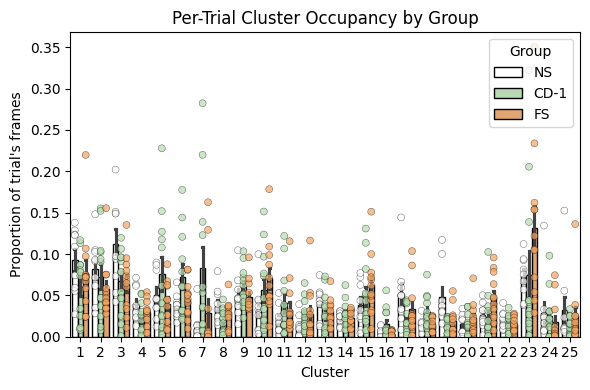

In [79]:
fig, ax = plt.subplots(figsize=(6,4))

# sns.boxplot(
#     data=long_df, x="cluster", y="proportion", hue="group",
#     palette=GROUP_COLORS, fliersize=0, linewidth=1, ax=ax,
# )
sns.barplot(
    data=long_df, x="cluster", y="proportion", hue="group",
    palette=GROUP_COLORS, linewidth=1, ax=ax,edgecolor='k',
    capsize=.1,errorbar='se'
)
sns.stripplot(
    data=long_df, x="cluster", y="proportion", hue="group",
    palette=GROUP_COLORS, dodge=True, size=5, alpha=0.7,jitter=0,
    linewidth=0.3, edgecolor="black", ax=ax,  # black edge (not white) so Group A's white fill still shows up
)

# boxplot + stripplot each add their own hue legend -- keep only one set, and
# relabel from "Group A/B/C" to the actual group names
handles, labels = ax.get_legend_handles_labels()
labels = [GROUP_LABELS.get(l, l) for l in labels[:len(groups)]]
ax.legend(handles[:len(groups)], labels, title="Group", loc="upper right")

ax.set_xlabel("Cluster")
ax.set_ylabel("Proportion of trial's frames")
ax.set_title(f"Per-Trial Cluster Occupancy by Group")
plt.tight_layout()
plt.savefig(FIG_DIR / 'barplot_cluster_occupancy.png')

In [80]:
long_df

,trial,cluster,proportion,group
0,raw_data-fs_sic_behavior_etho-trial_10,1,0.128540,Group A
1,raw_data-fs_sic_behavior_etho-trial_12,1,0.123686,Group A
2,raw_data-fs_sic_behavior_etho-trial_26,1,0.108976,Group A
3,raw_data-fs_sic_behavior_etho-trial_28,1,0.137871,Group A
4,raw_data-fs_sic_behavior_etho-trial_30,1,0.074137,Group A
...,...,...,...,...
820,raw_data-fs_sic_behavior_etho-trial_36,25,0.025110,Group C
821,raw_data-fs_sic_behavior_etho-trial_4,25,0.002986,Group C
822,raw_data-fs_sic_behavior_etho-trial_6,25,0.017274,Group C
823,raw_data-fs_sic_behavior_etho-trial_7,25,0.136212,Group C


In [81]:
pg.mixed_anova(data=long_df,dv='proportion',between='group',within='cluster',subject='trial')

,Source,SS,DF1,DF2,MS,F,p-unc,np2,eps
0,group,0.000000,2,30,0.000000,0.000000,1.000000e+00,0.000000,NaN
1,cluster,0.392827,24,720,0.016368,12.662296,5.944835e-41,0.296803,0.170803
2,Interaction,0.137372,48,720,0.002862,2.214004,8.565307e-06,0.128616,NaN


In [82]:
pg.pairwise_tests(data=long_df,dv='proportion',between='group',within='cluster',subject='trial',padjust='fdr_bh')

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:382: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  stats.loc[:, "A"] = A
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:383: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  stats.loc[:, "B"] = B
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data

,Contrast,cluster,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,cluster,-,1,2,True,True,1.233493,32.000000,two-sided,2.263757e-01,0.301834,fdr_bh,0.373,0.130878
1,cluster,-,1,3,True,True,-0.339693,32.000000,two-sided,7.363073e-01,0.794287,fdr_bh,0.197,-0.062426
2,cluster,-,1,4,True,True,6.457546,32.000000,two-sided,2.905606e-07,0.000004,fdr_bh,5.517e+04,1.316193
3,cluster,-,1,5,True,True,2.351188,32.000000,two-sided,2.503693e-02,0.046653,fdr_bh,2.022,0.416955
4,cluster,-,1,6,True,True,1.728068,32.000000,two-sided,9.361636e-02,0.142563,fdr_bh,0.707,0.532785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,cluster * group,24,Group A,Group C,False,True,0.747114,12.659004,two-sided,4.686452e-01,0.595735,fdr_bh,0.48,0.337571
374,cluster * group,24,Group B,Group C,False,True,0.638922,22.000000,two-sided,5.294700e-01,0.650988,fdr_bh,0.433,0.251845
375,cluster * group,25,Group A,Group B,False,True,1.243635,8.683004,two-sided,2.461610e-01,0.480424,fdr_bh,0.674,0.603143
376,cluster * group,25,Group A,Group C,False,True,0.359988,14.588172,two-sided,7.240147e-01,0.835402,fdr_bh,0.412,0.158395


In [83]:
# --- linear mixed-effects model of cluster occupancy: proportion ~ cluster x group,
# with a random intercept per trial (the 8 proportions of a trial are repeated measures) ---
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests

lme_df = long_df.copy()
lme_df["group_label"] = lme_df["group"].map(lambda g: GROUP_LABELS.get(g, g))
lme_df["cell"] = "cluster " + lme_df["cluster"].astype(str) + " | " + lme_df["group_label"]
lme_clusters = sorted(lme_df["cluster"].unique())
lme_groups = [GROUP_LABELS.get(g, g) for g in groups]

# 1) does occupancy differ between groups? Likelihood-ratio test of the cluster x group
#    interaction (both models fitted with ML, as the test requires). A trial's proportions
#    sum to 1, so there is no group main effect to test: the interaction IS the group effect.
with_interaction = smf.mixedlm("proportion ~ C(cluster) * C(group_label)", lme_df, groups=lme_df["trial"]).fit(reml=False, method="powell")
without_interaction = smf.mixedlm("proportion ~ C(cluster) + C(group_label)", lme_df, groups=lme_df["trial"]).fit(reml=False, method="powell")
lr = 2 * (with_interaction.llf - without_interaction.llf)
lr_df = (len(lme_clusters) - 1) * (len(lme_groups) - 1)
print(f"cluster x group interaction: chi2({lr_df}) = {lr:.2f}, p = {chi2.sf(lr, lr_df):.4g}")

# 2) the same model written with one coefficient per cluster-and-group cell (its estimated
#    mean proportion), fitted with REML, so a group difference within a cluster is just the
#    difference of two coefficients
cell_design = pd.get_dummies(lme_df["cell"]).astype(float)
lme = sm.MixedLM(lme_df["proportion"].astype(float), cell_design, groups=lme_df["trial"]).fit(reml=True, method="powell")
print(f"between-trial variance {float(lme.cov_re.iloc[0, 0]):.2g}, residual variance {float(lme.scale):.2g}")

rows = []
for cluster in lme_clusters:
    for i, a in enumerate(lme_groups):
        for b in lme_groups[i + 1:]:
            vector = pd.Series(0.0, index=lme.fe_params.index)       # one entry per fixed effect
            vector[f"cluster {cluster} | {a}"], vector[f"cluster {cluster} | {b}"] = 1.0, -1.0
            test = lme.t_test(vector.to_numpy()[None, :])
            low, high = np.ravel(test.conf_int())
            rows.append({"cluster": cluster, "A": a, "B": b, "difference (A - B)": float(np.ravel(test.effect)[0]),
                         "SE": float(np.ravel(test.sd)[0]), "95% low": float(low), "95% high": float(high),
                         "p": float(np.ravel(test.pvalue)[0])})
lme_pairwise = pd.DataFrame(rows)
lme_pairwise["p (FDR-BH)"] = multipletests(lme_pairwise["p"], method="fdr_bh")[1]
lme_pairwise.round(4)


/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


cluster x group interaction: chi2(48) = 113.58, p = 3.088e-07
between-trial variance 2.8e-12, residual variance 0.0012


/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


,cluster,A,B,difference (A - B),SE,95% low,95% high,p,p (FDR-BH)
0,1,NS,CD-1,0.0327,0.0155,0.0023,0.0632,0.0352,0.2201
1,1,NS,FS,0.0154,0.0155,-0.0150,0.0459,0.3210,0.7029
2,1,CD-1,FS,-0.0173,0.0144,-0.0455,0.0109,0.2290,0.7029
3,2,NS,CD-1,0.0090,0.0155,-0.0214,0.0394,0.5622,0.8257
4,2,NS,FS,0.0239,0.0155,-0.0065,0.0544,0.1236,0.5245
...,...,...,...,...,...,...,...,...,...
70,24,NS,FS,0.0116,0.0155,-0.0189,0.0420,0.4557,0.7767
71,24,CD-1,FS,0.0072,0.0144,-0.0209,0.0354,0.6145,0.8257
72,25,NS,CD-1,0.0202,0.0155,-0.0102,0.0507,0.1926,0.6565
73,25,NS,FS,0.0069,0.0155,-0.0236,0.0373,0.6571,0.8497


## Cluster occupancy with significant group differences

`pg.pairwise_tests` (group comparisons within each cluster, FDR-corrected): stars for p-corr < 0.05, the p-value for trends up to 0.1. Sized for a 2 × 1.5 in panel. 


/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:382: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  stats.loc[:, "A"] = A
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:383: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  stats.loc[:, "B"] = B
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data

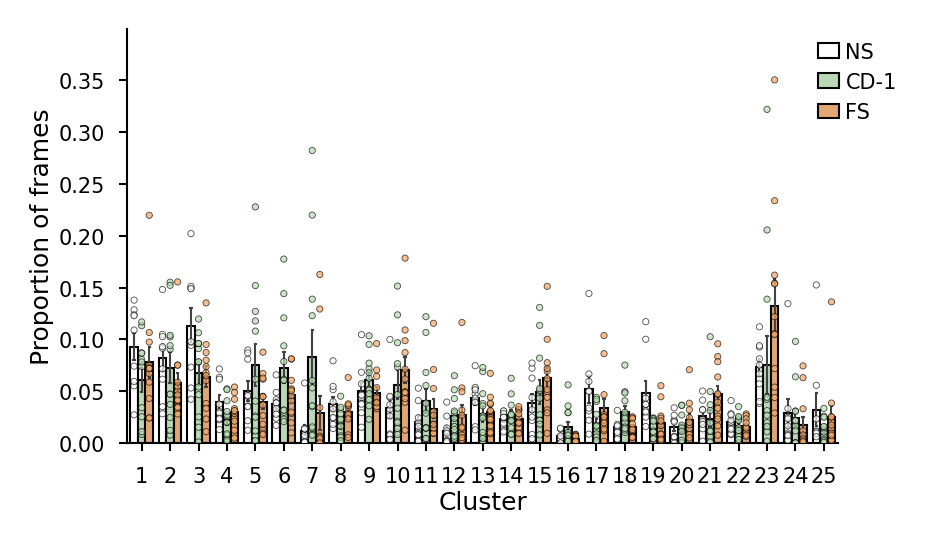

0 significant pair(s) (p-corr < 0.05, FDR-BH; * <0.05, ** <0.01, *** <0.001) and 0 trend(s) (0.05 <= p-corr < 0.1, labeled with the p-value):


,cluster,A,B,T,dof,p-unc,p-corr,hedges


In [84]:
# --- occupancy bar plot again, with the significant group differences within
# each cluster marked: the "cluster * group" rows of pg.pairwise_tests above,
# FDR-corrected (p-corr). Stars for p-corr < ALPHA, the p-value itself for
# trends up to TREND_ALPHA. Sized for a small figure panel. ---
ALPHA = 0.05        # marked with stars
TREND_ALPHA = 0.1   # 0.05 <= p-corr < 0.1: marked with the p-value, no stars
SAVE_PATH_SIG = FIG_DIR / "cluster_occupancy_significance.png"  # set to None to skip saving (.pdf/.svg also work)

# --- size settings (all in points unless noted) ---
FIGSIZE = (3, 1.7)      # inches, final saved size
DPI = 300
LABEL_FONT = 6          # axis labels
TICK_FONT = 5           # tick labels
LEGEND_FONT = 5
STAR_FONT = 7
PVALUE_FONT = 4.5
TITLE = None            # e.g. "Cluster occupancy"; None = no title (saves space)
LINE_WIDTH = 0.5        # bar edges, error bars, brackets, axes
POINT_SIZE = 1.5          # per-trial dots
CAPSIZE = 0.15          # error bar cap width, as a fraction of a bar

df = long_df.copy()
posthoc = pg.pairwise_tests(data=df, dv="proportion", between="group", within="cluster",
                            subject="trial", padjust="fdr_bh")
sig = posthoc[(posthoc["Contrast"] == "cluster * group") & (posthoc["p-corr"] < TREND_ALPHA)]


def p_label(p):
    if p >= ALPHA:
        return f"p={p:.3f}"
    return "***" if p < 0.001 else "**" if p < 0.01 else "*"


cluster_order = sorted(long_df["cluster"].unique())
hue_order = groups
with plt.rc_context({"axes.linewidth": LINE_WIDTH, "xtick.major.width": LINE_WIDTH,
                     "ytick.major.width": LINE_WIDTH, "xtick.major.size": 2, "ytick.major.size": 2,
                     "xtick.labelsize": TICK_FONT, "ytick.labelsize": TICK_FONT,
                     "axes.labelsize": LABEL_FONT, "axes.titlesize": LABEL_FONT}):
    fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout="constrained")

    sns.barplot(
        data=long_df, x="cluster", y="proportion", hue="group", order=cluster_order, hue_order=hue_order,
        palette=GROUP_COLORS, linewidth=LINE_WIDTH, ax=ax, edgecolor="k",
        capsize=CAPSIZE, errorbar="se", err_kws={"linewidth": LINE_WIDTH},
    )
    sns.stripplot(
        data=long_df, x="cluster", y="proportion", hue="group", order=cluster_order, hue_order=hue_order,
        palette=GROUP_COLORS, dodge=True, size=POINT_SIZE, alpha=0.7, jitter=0,
        linewidth=0.2, edgecolor="black", ax=ax,
    )

    # x position of each group's bar within a cluster (seaborn's default dodge:
    # the 0.8-wide slot split evenly between the groups)
    bar_width = 0.8 / len(hue_order)
    def bar_x(cluster, group):
        return cluster_order.index(cluster) + (hue_order.index(group) - (len(hue_order) - 1) / 2) * bar_width

    y_step = 0.07 * long_df["proportion"].max()   # vertical spacing between stacked brackets
    n_in_cluster = {}
    for _, row in sig.iterrows():
        cluster = type(cluster_order[0])(row["cluster"])  # pingouin may return the cluster id as a string
        x1, x2 = sorted([bar_x(cluster, row["A"]), bar_x(cluster, row["B"])])
        k = n_in_cluster.get(cluster, 0); n_in_cluster[cluster] = k + 1
        y = long_df.loc[long_df["cluster"] == cluster, "proportion"].max() + y_step * (1 + 1.8 * k)
        ax.plot([x1, x1, x2, x2], [y, y + y_step / 3, y + y_step / 3, y], color="k", linewidth=LINE_WIDTH)
        is_sig = row["p-corr"] < ALPHA
        ax.text((x1 + x2) / 2, y + y_step / 3 - (y_step * 0.25 if is_sig else 0), p_label(row["p-corr"]),
                ha="center", va="bottom", fontsize=STAR_FONT if is_sig else PVALUE_FONT)

    ax.set_ylim(top=max(ax.get_ylim()[1], long_df["proportion"].max() + y_step * (2 + 1.8 * max(n_in_cluster.values(), default=0))))

    # legend as one row above the plot -- no room beside it at this size
    handles, labels = ax.get_legend_handles_labels()
    labels = [GROUP_LABELS.get(l, l) for l in labels[:len(groups)]]
    ax.legend(handles[:len(groups)], labels, loc="upper right", bbox_to_anchor=(1.1, 1.0), ncols=1,
              fontsize=LEGEND_FONT, frameon=False, handlelength=1, handleheight=0.7, columnspacing=0.8,
              handletextpad=0.3, borderaxespad=0.2)
    ax.set_xlabel("Cluster", labelpad=1)
    ax.set_ylabel("Proportion of frames", labelpad=1)
    if TITLE:
        ax.set_title(TITLE, pad=12)
    sns.despine(ax=ax)

    if SAVE_PATH_SIG:
        fig.savefig(SAVE_PATH_SIG, dpi=DPI)   # no bbox_inches="tight": keeps exactly FIGSIZE
    plt.show()

print(f"{(sig['p-corr'] < ALPHA).sum()} significant pair(s) (p-corr < {ALPHA}, FDR-BH; * <0.05, ** <0.01, *** <0.001) "
      f"and {(sig['p-corr'] >= ALPHA).sum()} trend(s) ({ALPHA} <= p-corr < {TREND_ALPHA}, labeled with the p-value):")
sig[["cluster", "A", "B", "T", "dof", "p-unc", "p-corr", "hedges"]].assign(
    A=sig["A"].map(GROUP_LABELS), B=sig["B"].map(GROUP_LABELS))

## Per-group density with the clusters

Each group's own density (normalized within the group), with the clusters outlined and numbered. Sized for a 3 × 1.2 in panel.

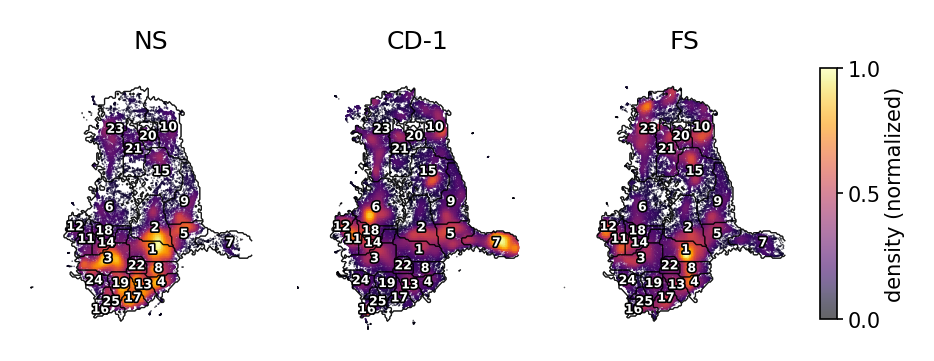

Per-group density with 25 chosen clusters (density normalized within each group); frames per group: NS 51472, CD-1 87611, FS 71997


In [85]:
SAVE_PATH = FIG_DIR / "density_heatmaps_groups.png"  # set to None to skip saving (.pdf/.svg also work)

# --- size settings (all in points unless noted) ---
FIGSIZE = (3, 1.2)      # inches, final saved size; panels are width-limited, so taller only adds white space
DPI = 300
TITLE_FONT = 6          # group name above each panel
LABEL_FONT = 6          # axis labels
TICK_FONT = 5           # tick labels (colorbar, and the UMAP axes if SHOW_TICKS)
CLUSTER_FONT = 3      # cluster numbers
POINT_SIZE = 0.15       # marker area, points^2 (was 3 at full size)
OUTLINE_WIDTH = 0.3     # cluster boundaries
SHOW_TICKS = False      # UMAP axes are in arbitrary units, so no tick numbers by default

with plt.rc_context({"axes.linewidth": 0.4, "xtick.major.width": 0.4, "ytick.major.width": 0.4,
                     "xtick.major.size": 1.5, "ytick.major.size": 1.5,
                     "xtick.labelsize": TICK_FONT, "ytick.labelsize": TICK_FONT,
                     "axes.labelsize": LABEL_FONT, "axes.titlesize": TITLE_FONT}):
    fig, axes = plt.subplots(1, len(groups), figsize=FIGSIZE, dpi=DPI, layout="constrained",
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)

    for ax, group in zip(axes, groups):
        in_group = (meta["group"] == group).to_numpy()
        gx, gy = embedding[in_group, 0], embedding[in_group, 1]
        density, _ = per_point_density(gx, gy, DENSITY_BINS, DENSITY_GAUSSIAN_STDDEV, xlim, ylim)
        density[density== 0] = np.nan    
        order = np.argsort(density)  # draw densest points last so they aren't buried

        cmap = plt.get_cmap("inferno").copy()
        cmap.set_bad("white")
        scatter = ax.scatter(gx[order], gy[order], c=density[order], cmap=cmap, norm=Normalize(0, 1),
                             s=POINT_SIZE, alpha=0.6, linewidths=0,
                             rasterized=True)  # points as an image inside .pdf/.svg, so the file stays small

        # the clusters chosen above, drawn and numbered the same way as in explore()
        draw_cluster_outlines(ax, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=OUTLINE_WIDTH)
        label_cluster_centroids(ax, embedding, chosen_point_clusters, text_color="white", outline_color="black",
                                fontsize=CLUSTER_FONT, stroke_width=0.8)

        ax.set_xlim(ZOOM_XLIM or xlim); ax.set_ylim(ZOOM_YLIM or ylim)
        ax.set_aspect("equal")
        ax.set_facecolor("white")
        ax.set_title(GROUP_LABELS.get(group, group), pad=2)
        if not SHOW_TICKS:
            ax.set_xticks([]); ax.set_yticks([])
            ax.axis("off")
    axes[len(axes) // 2].set_xlabel("UMAP 1", labelpad=1)
    axes[0].set_ylabel("UMAP 2", labelpad=1)
    cbar = fig.colorbar(scatter, ax=axes, ticks=[0, 0.5, 1], shrink=0.75, aspect=15, pad=0.02)
    cbar.set_label("density (normalized)", fontsize=TICK_FONT, labelpad=1)
    cbar.ax.tick_params(labelsize=TICK_FONT, width=0.4, length=1.5, pad=1)
    cbar.outline.set_linewidth(0.4)

    if SAVE_PATH:
        fig.savefig(SAVE_PATH, dpi=DPI)   # no bbox_inches="tight": keeps exactly FIGSIZE
    plt.show()

print(f"Per-group density with {len(cluster_ids)} chosen clusters (density normalized within each group); "
      f"frames per group: " + ", ".join(f"{GROUP_LABELS.get(g, g)} {(meta['group'] == g).sum()}" for g in groups))

## Density and behavior maps, per group (3 × 3.5 in panel)

One row per group: that group's own density (left) and its frames colored by behavior family (right), with the clusters outlined and numbered on both. The full per-behavior color legend is saved as a separate file.

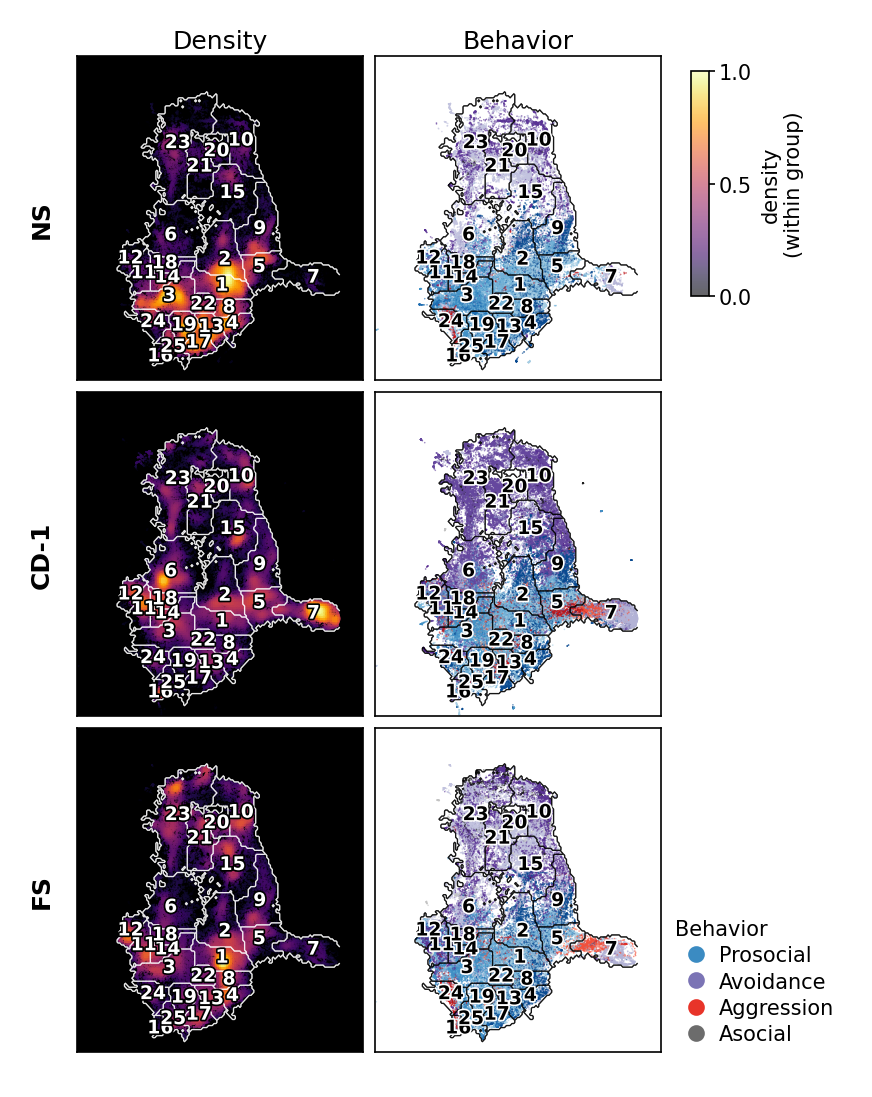

panels 0.95 x 1.08 in; 25 chosen clusters; rows: NS, CD-1, FS; saved figures/density_behavior_grid.png and figures/density_behavior_grid_legend.png


In [86]:
# --- density (left) and behavior-colored (right) maps side by side, one row
# per group, with the chosen clusters outlined on both ---
GRID_SAVE_PATH = FIG_DIR / "density_behavior_grid.png"                # set to None to skip saving (.pdf/.svg also work)
GRID_LEGEND_SAVE_PATH = FIG_DIR / "density_behavior_grid_legend.png"  # full per-behavior legend, as its own file; None to skip
GRID_LEGEND_COLUMNS = 2    # columns in that legend (filled top to bottom, then left to right)

# --- size settings (fonts/lines in points, layout in inches) ---
GRID_FIGSIZE = (3, 3.5)     # inches, final saved size
GRID_DPI = 300
GRID_TITLE_FONT = 6         # column titles, row (group) labels
GRID_TICK_FONT = 5          # colorbar ticks, legend text
GRID_CLUSTER_FONT = 4.5     # cluster numbers
GRID_POINT_SIZE = 0.15      # marker area, points^2
GRID_OUTLINE_WIDTH = 0.3    # cluster boundaries
MARGIN_LEFT, MARGIN_TOP, MARGIN_BOTTOM = 0.17, 0.14, 0.04   # room for row labels / column titles
GAP = 0.04                  # between panels
RIGHT_STRIP = 0.62          # minimum width kept on the right for the colorbar + legend

# one representative (middle) shade per behavior family, for the compact in-figure legend
family_colors = {family: plt.get_cmap(FAMILY_CMAP_NAME[family])(0.65) for family in FAMILY_ORDER}

# panel size: as large as fits, keeping x and y on the same scale
map_xlim, map_ylim = (ZOOM_XLIM or xlim), (ZOOM_YLIM or ylim)
aspect = (map_ylim[1] - map_ylim[0]) / (map_xlim[1] - map_xlim[0])   # panel height / width
fig_w, fig_h = GRID_FIGSIZE
n_rows = len(groups)
panel_h = min((fig_h - MARGIN_TOP - MARGIN_BOTTOM - (n_rows - 1) * GAP) / n_rows,
              (fig_w - MARGIN_LEFT - GAP - RIGHT_STRIP) / 2 * aspect)
panel_w = panel_h / aspect

with plt.rc_context({"axes.linewidth": 0.4, "axes.titlesize": GRID_TITLE_FONT,
                     "axes.labelsize": GRID_TITLE_FONT}):
    fig = plt.figure(figsize=GRID_FIGSIZE, dpi=GRID_DPI)
    axes = np.empty((n_rows, 2), dtype=object)
    top = fig_h - MARGIN_TOP
    for row in range(n_rows):
        bottom = top - (row + 1) * panel_h - row * GAP
        for col in range(2):
            left = MARGIN_LEFT + col * (panel_w + GAP)
            axes[row, col] = fig.add_axes([left / fig_w, bottom / fig_h, panel_w / fig_w, panel_h / fig_h])

    for row, group in enumerate(groups):
        in_group = (meta["group"] == group).to_numpy()
        gx, gy = embedding[in_group, 0], embedding[in_group, 1]

        # left: this group's own density, normalized within the group
        ax = axes[row, 0]
        density, _ = per_point_density(gx, gy, DENSITY_BINS, DENSITY_GAUSSIAN_STDDEV, xlim, ylim)
        order = np.argsort(density)  # draw densest points last so they aren't buried
        density_scatter = ax.scatter(gx[order], gy[order], c=density[order], cmap="inferno", norm=Normalize(0, 1),
                                     s=GRID_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
        ax.set_facecolor("black")
        draw_cluster_outlines(ax, chosen_clusters, chosen_hx, chosen_hy, color="white", linewidth=GRID_OUTLINE_WIDTH)
        label_cluster_centroids(ax, embedding, chosen_point_clusters, text_color="white", outline_color="black",
                                fontsize=GRID_CLUSTER_FONT, stroke_width=0.8)
        ax.set_ylabel(GROUP_LABELS.get(group, group), fontweight="bold", labelpad=2)

        # right: this group's frames colored by resident behavior (family palette), unannotated in light gray
        ax = axes[row, 1]
        codes = behavior_codes[in_group]
        unannotated = codes < 0
        ax.scatter(gx[unannotated], gy[unannotated], color="0.9", s=GRID_POINT_SIZE, alpha=0.3,
                   linewidths=0, rasterized=True)
        annotated = ~unannotated
        order = np.random.default_rng(0).permutation(annotated.sum())  # shuffle so no behavior always draws on top
        ax.scatter(gx[annotated][order], gy[annotated][order], c=codes[annotated][order], cmap=behavior_cmap,
                   vmin=0, vmax=len(ordered_behaviors) - 1, s=GRID_POINT_SIZE, alpha=0.6, linewidths=0,
                   rasterized=True)
        draw_cluster_outlines(ax, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=GRID_OUTLINE_WIDTH)
        label_cluster_centroids(ax, embedding, chosen_point_clusters, text_color="black", outline_color="white",
                                fontsize=GRID_CLUSTER_FONT, stroke_width=0.8)

    for ax in axes.flat:
        ax.set_xlim(map_xlim); ax.set_ylim(map_ylim)
        ax.set_xticks([]); ax.set_yticks([])  # UMAP axes are in arbitrary units
    axes[0, 0].set_title("Density", pad=2)
    axes[0, 1].set_title("Behavior", pad=2)

    # right strip: density colorbar beside the top row, behavior-family legend beside the bottom row
    strip_left = MARGIN_LEFT + 2 * panel_w + GAP + 0.1
    cbar_ax = fig.add_axes([strip_left / fig_w, (top - 0.05 - 0.75) / fig_h, 0.06 / fig_w, 0.75 / fig_h])
    cbar = fig.colorbar(density_scatter, cax=cbar_ax, ticks=[0, 0.5, 1])
    cbar.set_label("density\n(within group)", fontsize=GRID_TICK_FONT, labelpad=2)
    cbar.ax.tick_params(labelsize=GRID_TICK_FONT, width=0.4, length=1.5, pad=1)
    cbar.outline.set_linewidth(0.4)

    family_handles = [plt.Line2D([0], [0], marker="o", linestyle="", markersize=3, color=family_colors[f])
                      for f in FAMILY_ORDER]
    fig.legend(family_handles, FAMILY_ORDER, loc="lower left",
               bbox_to_anchor=((strip_left - 0.08) / fig_w, (top - n_rows * panel_h - (n_rows - 1) * GAP) / fig_h),
               fontsize=GRID_TICK_FONT, frameon=False, handletextpad=0.1, borderaxespad=0, labelspacing=0.3,
               title="Behavior", title_fontsize=GRID_TICK_FONT, alignment="left")

    if GRID_SAVE_PATH:
        fig.savefig(GRID_SAVE_PATH, dpi=GRID_DPI)   # no bbox_inches="tight": keeps exactly GRID_FIGSIZE
    plt.show()

# full per-behavior legend (every shade), saved as its own small figure to place beside the grid
if GRID_LEGEND_SAVE_PATH:
    rows_per_column = int(np.ceil(len(ordered_behaviors) / GRID_LEGEND_COLUMNS))
    legend_fig = plt.figure(figsize=(1.3 * GRID_LEGEND_COLUMNS, 0.1 + 0.075 * rows_per_column), dpi=GRID_DPI)
    behavior_handles = [plt.Line2D([0], [0], marker="o", linestyle="", markersize=3, color=behavior_colors[i])
                        for i in range(len(ordered_behaviors))]
    legend_fig.legend(behavior_handles, ordered_behaviors, loc="center left", fontsize=GRID_TICK_FONT,
                      ncol=GRID_LEGEND_COLUMNS, columnspacing=0.8,
                      frameon=False, handletextpad=0.2, labelspacing=0.25, borderaxespad=0)
    legend_fig.savefig(GRID_LEGEND_SAVE_PATH, dpi=GRID_DPI, bbox_inches="tight")
    plt.close(legend_fig)

print(f"panels {panel_w:.2f} x {panel_h:.2f} in; {len(cluster_ids)} chosen clusters; rows: "
      + ", ".join(GROUP_LABELS.get(g, g) for g in groups)
      + (f"; saved {GRID_SAVE_PATH}" if GRID_SAVE_PATH else "")
      + (f" and {GRID_LEGEND_SAVE_PATH}" if GRID_LEGEND_SAVE_PATH else ""))

## Cluster overview at the chosen settings

The same three panels the `explore()` sliders draw in `explore_watershed.ipynb` (points by cluster, density with cluster boundaries, points by behavior), at `CHOSEN`.

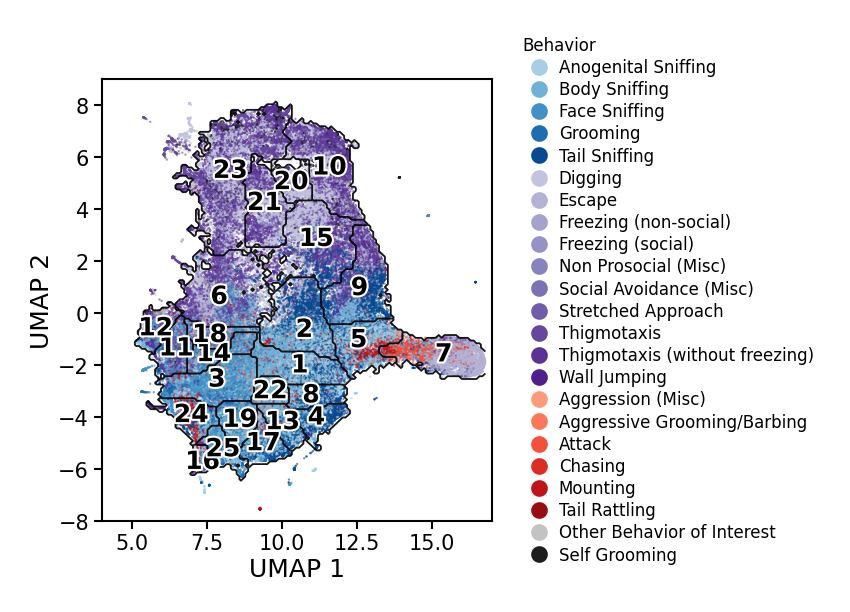

WatershedConfig(bins=200, gaussian_stddev=2, num_clusters=25, compactness=0.05); map 1.30 x 1.47 in


In [87]:
BEHAVIOR_MAP_SAVE_PATH = FIG_DIR / "behavior_map.png"
BEHAVIOR_MAP_DPI = 300

# --- size settings (fonts/lines in points, layout in inches) ---
BEHAVIOR_MAP_FIGSIZE = (3,3)   # one ~2.0 x 2.3 in map plus the legend strip
OV_TITLE_FONT = 7             # panel title
OV_LABEL_FONT = 6             # axis labels
OV_TICK_FONT = 5              # tick labels
OV_LEGEND_FONT = 4            # behavior legend
OV_CLUSTER_FONT = 6           # cluster numbers
OV_POINT_SIZE = 0.3           # marker area, points^2
OV_OUTLINE_WIDTH = 0.4        # cluster boundaries
OV_MARGIN_LEFT, OV_MARGIN_BOTTOM, OV_MARGIN_TOP = 0.35, 0.32, 0.28
OV_LEGEND_STRIP = 1.35        # width kept on the right for the behavior legend

# map limits (the shared zoom, or the full embedding) and panel size: as large
# as fits, keeping x and y on the same scale
aspect = (map_ylim[1] - map_ylim[0]) / (map_xlim[1] - map_xlim[0])
fig_w, fig_h = BEHAVIOR_MAP_FIGSIZE
panel_w = min(fig_w - OV_MARGIN_LEFT - OV_LEGEND_STRIP,
              (fig_h - OV_MARGIN_BOTTOM - OV_MARGIN_TOP) / aspect)
panel_h = panel_w * aspect

with plt.rc_context({"axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2, "ytick.major.size": 2,
                     "xtick.labelsize": OV_TICK_FONT, "ytick.labelsize": OV_TICK_FONT,
                     "axes.labelsize": OV_LABEL_FONT, "axes.titlesize": OV_TITLE_FONT}):
    fig = plt.figure(figsize=BEHAVIOR_MAP_FIGSIZE, dpi=BEHAVIOR_MAP_DPI)
    ax = fig.add_axes([OV_MARGIN_LEFT / fig_w, OV_MARGIN_BOTTOM / fig_h, panel_w / fig_w, panel_h / fig_h])

    unannotated = behavior_codes < 0
    ax.scatter(embedding[unannotated, 0], embedding[unannotated, 1], color="0.9", s=OV_POINT_SIZE, alpha=0.3,
               linewidths=0, rasterized=True)
    annotated = ~unannotated
    behavior_order = np.random.default_rng(0).permutation(annotated.sum())
    ax.scatter(embedding[annotated, 0][behavior_order], embedding[annotated, 1][behavior_order],
               c=behavior_codes[annotated][behavior_order], cmap=behavior_cmap,
               vmin=0, vmax=len(ordered_behaviors) - 1, s=OV_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
    draw_cluster_outlines(ax, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=OV_OUTLINE_WIDTH)
    label_cluster_centroids(ax, embedding, chosen_point_clusters, text_color="black", outline_color="white",
                            fontsize=OV_CLUSTER_FONT, stroke_width=1)

    ax.set_xlim([4,17]); ax.set_ylim([-8,9])
    ax.set_xlabel("UMAP 1", labelpad=1)
    ax.set_ylabel("UMAP 2", labelpad=1)
    ax.tick_params(pad=1)

    handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=behavior_colors[i], markersize=3)
               for i in range(len(ordered_behaviors))]
    legend_left = OV_MARGIN_LEFT + panel_w + 0.08
    fig.legend(handles, ordered_behaviors, loc="center left",
               bbox_to_anchor=(legend_left / fig_w, (OV_MARGIN_BOTTOM + panel_h / 2) / fig_h),
               fontsize=OV_LEGEND_FONT, frameon=False, handletextpad=0.2, labelspacing=0.25, borderaxespad=0,
               title="Behavior", title_fontsize=OV_LEGEND_FONT, alignment="left")

    fig.savefig(BEHAVIOR_MAP_SAVE_PATH, dpi=BEHAVIOR_MAP_DPI)
    plt.show()

print(f"{CHOSEN}; map {panel_w:.2f} x {panel_h:.2f} in")

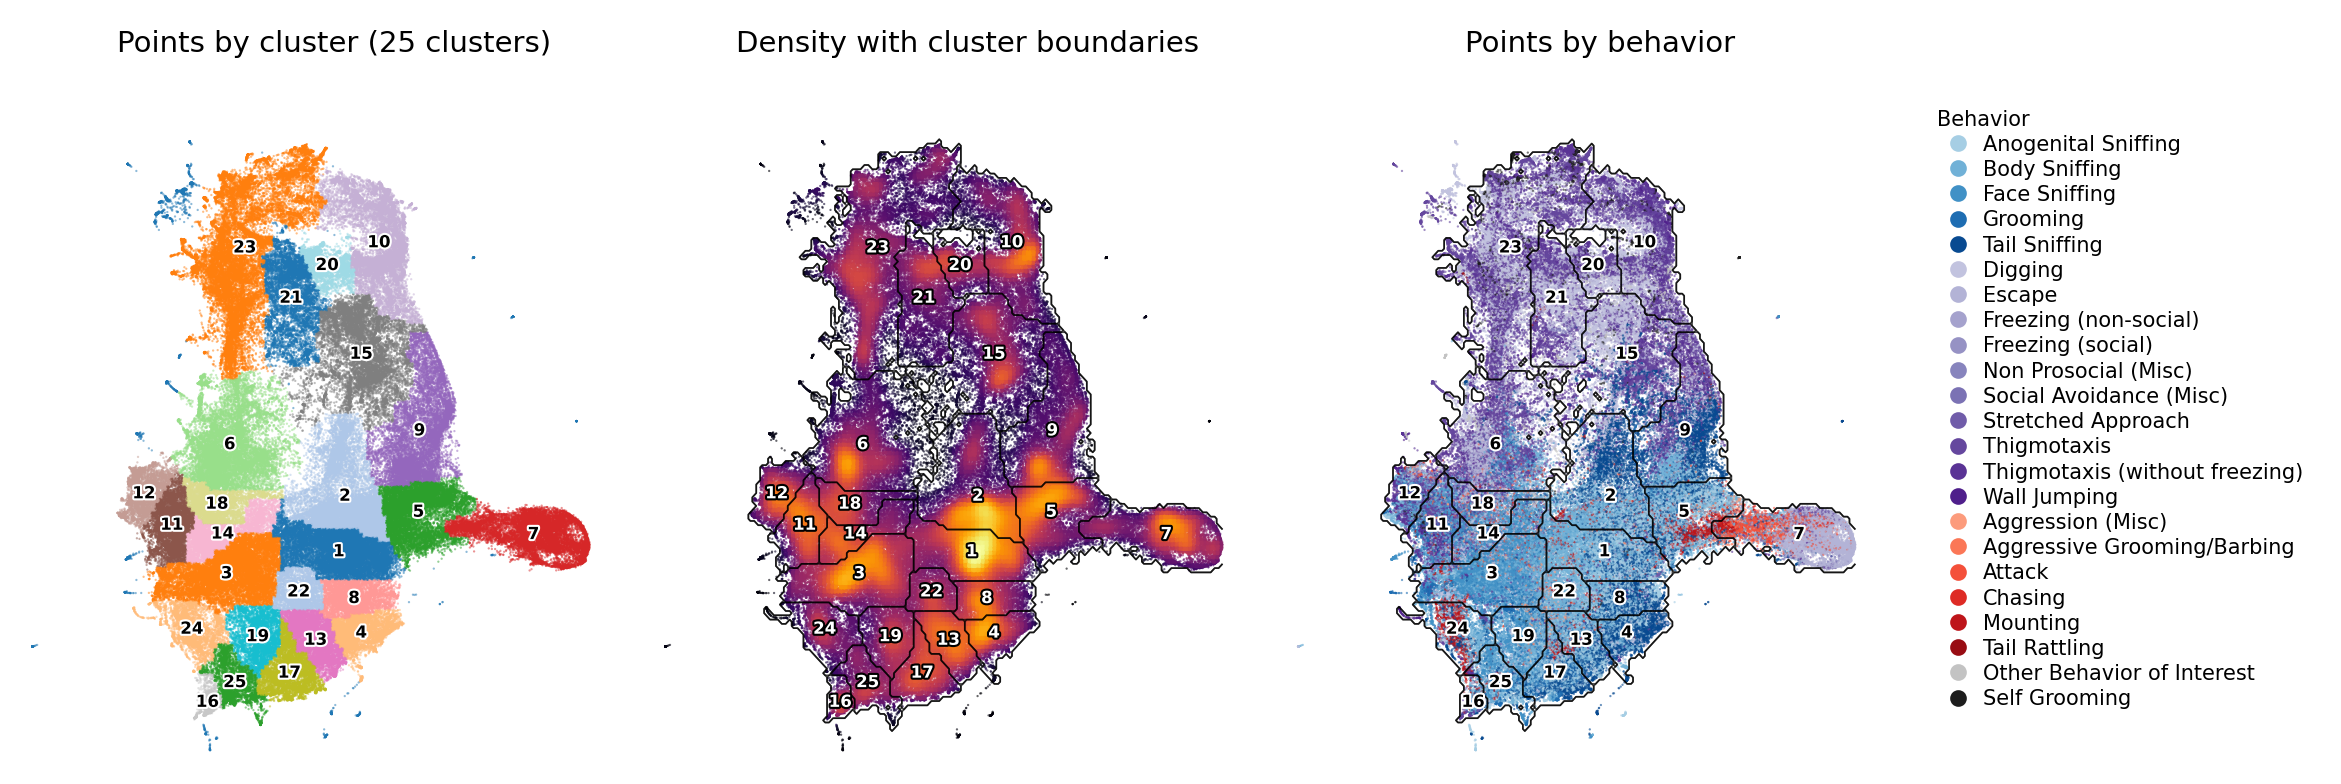

WatershedConfig(bins=200, gaussian_stddev=2, num_clusters=25, compactness=0.05); maps 2.03 x 2.30 in; largest cluster holds 10.6% of points, smallest 0.8%


In [95]:
from astropy.convolution import Gaussian2DKernel, convolve_fft

OVERVIEW_SAVE_PATH = FIG_DIR / "cluster_overview_supp.png"   # set to None to skip saving (.pdf/.svg also work)
OVERVIEW_DPI = 300

# --- size settings (fonts/lines in points, layout in inches) ---
OVERVIEW_FIGSIZE = (8, 2.9)   # 2.9 in tall fits three ~2.0 x 2.3 in maps at the zoom below
OV_TITLE_FONT = 7             # panel titles
OV_LABEL_FONT = 6             # axis labels
OV_TICK_FONT = 5              # tick labels
OV_LEGEND_FONT = 5            # behavior legend
OV_CLUSTER_FONT = 4           # cluster numbers
OV_POINT_SIZE = 0.3           # marker area, points^2
OV_OUTLINE_WIDTH = 0.4        # cluster boundaries
OV_MARGIN_LEFT, OV_MARGIN_BOTTOM, OV_MARGIN_TOP = 0.35, 0.32, 0.28
OV_GAP = 0.08                 # between maps
OV_LEGEND_STRIP = 1.35        # width kept on the right for the behavior legend

cluster_colors = ListedColormap([plt.cm.tab20.colors[i % 20] for i in range(max(CHOSEN.num_clusters, 1))])

# smoothed density at each point, same bins/smoothing as the watershed itself
hist, hx, hy = np.histogram2d(embedding[:, 0], embedding[:, 1], bins=CHOSEN.bins)
smoothed = convolve_fft(hist, Gaussian2DKernel(x_stddev=CHOSEN.gaussian_stddev, y_stddev=CHOSEN.gaussian_stddev))
smoothed = smoothed / smoothed.max()
x_bins = np.clip(np.digitize(embedding[:, 0], hx) - 1, 0, CHOSEN.bins - 1)
y_bins = np.clip(np.digitize(embedding[:, 1], hy) - 1, 0, CHOSEN.bins - 1)
point_density = smoothed[x_bins, y_bins]

# map limits (the shared zoom, or the full embedding) and panel size: as large
# as fits, keeping x and y on the same scale
map_xlim = ZOOM_XLIM or (embedding[:, 0].min(), embedding[:, 0].max())
map_ylim = ZOOM_YLIM or (embedding[:, 1].min(), embedding[:, 1].max())
aspect = (map_ylim[1] - map_ylim[0]) / (map_xlim[1] - map_xlim[0])
fig_w, fig_h = OVERVIEW_FIGSIZE
panel_w = min((fig_w - OV_MARGIN_LEFT - 2 * OV_GAP - OV_LEGEND_STRIP) / 3,
              (fig_h - OV_MARGIN_BOTTOM - OV_MARGIN_TOP) / aspect)
panel_h = panel_w * aspect

with plt.rc_context({"axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2, "ytick.major.size": 2,
                     "xtick.labelsize": OV_TICK_FONT, "ytick.labelsize": OV_TICK_FONT,
                     "axes.labelsize": OV_LABEL_FONT, "axes.titlesize": OV_TITLE_FONT}):
    
    fig = plt.figure(figsize=OVERVIEW_FIGSIZE, dpi=OVERVIEW_DPI)
    axes = [fig.add_axes([(OV_MARGIN_LEFT + k * (panel_w + OV_GAP)) / fig_w, OV_MARGIN_BOTTOM / fig_h,
                          panel_w / fig_w, panel_h / fig_h]) for k in range(3)]
    ax1, ax2, ax3 = axes

    order = np.random.default_rng(0).permutation(len(embedding))  # shuffle so no cluster systematically draws on top
    ax1.scatter(embedding[order, 0], embedding[order, 1], c=chosen_point_clusters[order], cmap=cluster_colors,
                vmin=1, vmax=CHOSEN.num_clusters, s=OV_POINT_SIZE, alpha=0.5, linewidths=0, rasterized=True)
    label_cluster_centroids(ax1, embedding, chosen_point_clusters, text_color="black", outline_color="white",
                            fontsize=OV_CLUSTER_FONT, stroke_width=1)
    ax1.set_title(f"Points by cluster ({len(cluster_ids)} clusters)", pad=3)

    density_order = np.argsort(point_density)  # draw densest points last so they aren't buried
    ax2.scatter(embedding[density_order, 0], embedding[density_order, 1], c=point_density[density_order],
                cmap="inferno", norm=Normalize(0, 1), s=OV_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
    ax2.set_facecolor("black")
    draw_cluster_outlines(ax2, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=OV_OUTLINE_WIDTH)
    label_cluster_centroids(ax2, embedding, chosen_point_clusters, text_color="white", outline_color="black",
                            fontsize=OV_CLUSTER_FONT, stroke_width=1)
    ax2.set_title("Density with cluster boundaries", pad=3)


    unannotated = behavior_codes < 0
    ax3.scatter(embedding[unannotated, 0], embedding[unannotated, 1], color="0.9", s=OV_POINT_SIZE, alpha=0.3,
                linewidths=0, rasterized=True)
    annotated = ~unannotated
    behavior_order = np.random.default_rng(0).permutation(annotated.sum())
    ax3.scatter(embedding[annotated, 0][behavior_order], embedding[annotated, 1][behavior_order],
                c=behavior_codes[annotated][behavior_order], cmap=behavior_cmap,
                vmin=0, vmax=len(ordered_behaviors) - 1, s=OV_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
    draw_cluster_outlines(ax3, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=OV_OUTLINE_WIDTH)
    label_cluster_centroids(ax3, embedding, chosen_point_clusters, text_color="black", outline_color="white",
                            fontsize=OV_CLUSTER_FONT, stroke_width=1)
    ax3.set_title("Points by behavior", pad=3)

    for k, ax in enumerate(axes):
        ax.set_xlim(map_xlim); ax.set_ylim(map_ylim)
        ax.set_xlabel("UMAP 1", labelpad=1)
        ax.tick_params(pad=1)
        ax.set_facecolor("white")
        ax.axis('off')
        if k == 0:
            ax.set_ylabel("UMAP 2", labelpad=1)
        else:
            ax.tick_params(labelleft=False)   # same y scale as the first map

    handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=behavior_colors[i], markersize=3)
               for i in range(len(ordered_behaviors))]
    legend_left = OV_MARGIN_LEFT + 3 * panel_w + 2 * OV_GAP + 0.08
    fig.legend(handles, ordered_behaviors, loc="center left",
               bbox_to_anchor=(legend_left / fig_w, (OV_MARGIN_BOTTOM + panel_h / 2) / fig_h),
               fontsize=OV_LEGEND_FONT, frameon=False, handletextpad=0.2, labelspacing=0.25, borderaxespad=0,
               title="Behavior", title_fontsize=OV_LEGEND_FONT, alignment="left")

    if OVERVIEW_SAVE_PATH:
        fig.savefig(OVERVIEW_SAVE_PATH, dpi=OVERVIEW_DPI)   # no bbox_inches="tight": keeps exactly OVERVIEW_FIGSIZE
    plt.show()

sizes = pd.Series(chosen_point_clusters).value_counts(normalize=True).sort_values(ascending=False)
print(f"{CHOSEN}; maps {panel_w:.2f} x {panel_h:.2f} in; "
      f"largest cluster holds {sizes.iloc[0]:.1%} of points, smallest {sizes.iloc[-1]:.1%}")

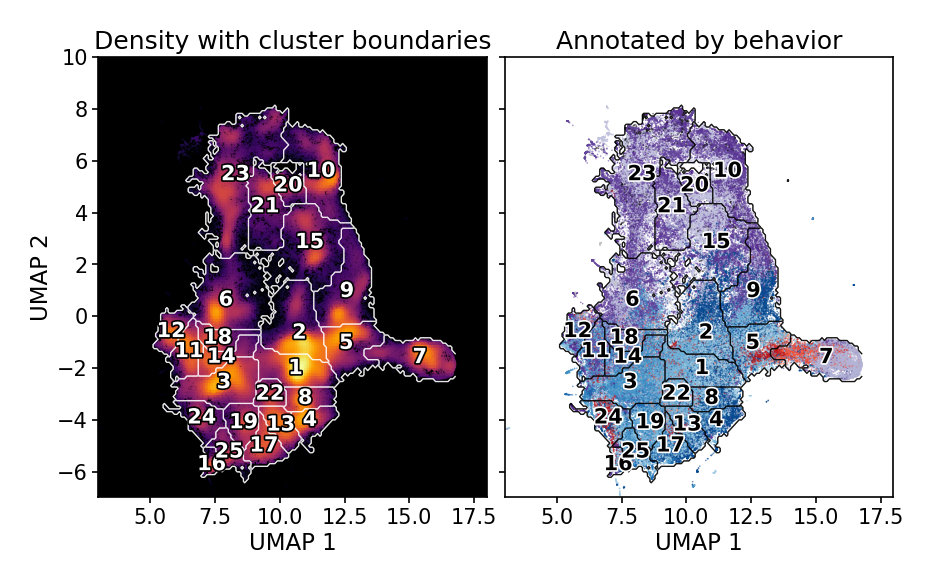

WatershedConfig(bins=200, gaussian_stddev=2, num_clusters=25, compactness=0.05); maps 1.30 x 1.47 in; largest cluster holds 10.6% of points, smallest 0.8%


In [96]:
from astropy.convolution import Gaussian2DKernel, convolve_fft

OVERVIEW_SAVE_PATH = FIG_DIR / "cluster_overview.png"   # set to None to skip saving (.pdf/.svg also work)
OVERVIEW_DPI = 300

# --- size settings (fonts/lines in points, layout in inches) ---
OVERVIEW_FIGSIZE = (3, 2)     # whole figure: two maps side by side
OV_TITLE_FONT = 6             # panel titles
OV_LABEL_FONT = 5.5           # axis labels
OV_TICK_FONT = 5              # tick labels
OV_LEGEND_FONT = 5            # behavior legend (separate figure)
OV_CLUSTER_FONT = 5           # cluster numbers
OV_POINT_SIZE = 0.15          # marker area, points^2
OV_OUTLINE_WIDTH = 0.3        # cluster boundaries
OV_MARGIN_LEFT, OV_MARGIN_BOTTOM, OV_MARGIN_TOP, OV_MARGIN_RIGHT = 0.3, 0.27, 0.2, 0.05
OV_GAP = 0.06                 # between maps

# smoothed density at each point, same bins/smoothing as the watershed itself
hist, hx, hy = np.histogram2d(embedding[:, 0], embedding[:, 1], bins=CHOSEN.bins)
smoothed = convolve_fft(hist, Gaussian2DKernel(x_stddev=CHOSEN.gaussian_stddev, y_stddev=CHOSEN.gaussian_stddev))
smoothed = smoothed / smoothed.max()
x_bins = np.clip(np.digitize(embedding[:, 0], hx) - 1, 0, CHOSEN.bins - 1)
y_bins = np.clip(np.digitize(embedding[:, 1], hy) - 1, 0, CHOSEN.bins - 1)
point_density = smoothed[x_bins, y_bins]

# map limits (the shared zoom, or the full embedding) and map size: as large as two maps fit
# in OVERVIEW_FIGSIZE, keeping x and y on the same scale
map_xlim = ZOOM_XLIM or (embedding[:, 0].min(), embedding[:, 0].max())
map_ylim = ZOOM_YLIM or (embedding[:, 1].min(), embedding[:, 1].max())
aspect = (map_ylim[1] - map_ylim[0]) / (map_xlim[1] - map_xlim[0])
fig_w, fig_h = OVERVIEW_FIGSIZE
panel_w = min((fig_w - OV_MARGIN_LEFT - OV_GAP - OV_MARGIN_RIGHT) / 2,
              (fig_h - OV_MARGIN_BOTTOM - OV_MARGIN_TOP) / aspect)
panel_h = panel_w * aspect

with plt.rc_context({"axes.linewidth": 0.4, "xtick.major.width": 0.4, "ytick.major.width": 0.4,
                     "xtick.major.size": 1.5, "ytick.major.size": 1.5,
                     "xtick.labelsize": OV_TICK_FONT, "ytick.labelsize": OV_TICK_FONT,
                     "axes.labelsize": OV_LABEL_FONT, "axes.titlesize": OV_TITLE_FONT}):
    fig = plt.figure(figsize=OVERVIEW_FIGSIZE, dpi=OVERVIEW_DPI)
    axes = [fig.add_axes([(OV_MARGIN_LEFT + k * (panel_w + OV_GAP)) / fig_w, OV_MARGIN_BOTTOM / fig_h,
                          panel_w / fig_w, panel_h / fig_h]) for k in range(2)]
    ax2, ax3 = axes

    density_order = np.argsort(point_density)  # draw densest points last so they aren't buried
    ax2.scatter(embedding[density_order, 0], embedding[density_order, 1], c=point_density[density_order],
                cmap="inferno", norm=Normalize(0, 1), s=OV_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
    ax2.set_facecolor("black")
    draw_cluster_outlines(ax2, chosen_clusters, chosen_hx, chosen_hy, color="white", linewidth=OV_OUTLINE_WIDTH)
    label_cluster_centroids(ax2, embedding, chosen_point_clusters, text_color="white", outline_color="black",
                            fontsize=OV_CLUSTER_FONT, stroke_width=0.8)
    ax2.set_title("Density with cluster boundaries", pad=2)

    unannotated = behavior_codes < 0
    ax3.scatter(embedding[unannotated, 0], embedding[unannotated, 1], color="0.9", s=OV_POINT_SIZE, alpha=0.3,
                linewidths=0, rasterized=True)
    annotated = ~unannotated
    behavior_order = np.random.default_rng(0).permutation(annotated.sum())
    ax3.scatter(embedding[annotated, 0][behavior_order], embedding[annotated, 1][behavior_order],
                c=behavior_codes[annotated][behavior_order], cmap=behavior_cmap,
                vmin=0, vmax=len(ordered_behaviors) - 1, s=OV_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
    draw_cluster_outlines(ax3, chosen_clusters, chosen_hx, chosen_hy, color="black", linewidth=OV_OUTLINE_WIDTH)
    label_cluster_centroids(ax3, embedding, chosen_point_clusters, text_color="black", outline_color="white",
                            fontsize=OV_CLUSTER_FONT, stroke_width=0.8)
    ax3.set_title("Annotated by behavior", pad=2)

    for k, ax in enumerate(axes):
        ax.set_xlim(map_xlim); ax.set_ylim(map_ylim)
        ax.set_xlabel("UMAP 1", labelpad=1)
        ax.tick_params(pad=1)
        if k == 0:
            ax.set_ylabel("UMAP 2", labelpad=1)
        else:
            ax.tick_params(labelleft=False)   # same y scale as the first map

    if OVERVIEW_SAVE_PATH:
        fig.savefig(OVERVIEW_SAVE_PATH, dpi=OVERVIEW_DPI)   # no bbox_inches="tight": keeps exactly OVERVIEW_FIGSIZE
    plt.show()

sizes = pd.Series(chosen_point_clusters).value_counts(normalize=True).sort_values(ascending=False)
print(f"{CHOSEN}; maps {panel_w:.2f} x {panel_h:.2f} in; "
      f"largest cluster holds {sizes.iloc[0]:.1%} of points, smallest {sizes.iloc[-1]:.1%}")

In [97]:
%matplotlib inline
LEGEND_NCOL = 1          # columns; 2 makes it shorter and wider
LEGEND_MARKER = 3        # dot size
LEGEND_FONT = OV_LEGEND_FONT

handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=behavior_colors[i], markersize=LEGEND_MARKER)
           for i in range(len(ordered_behaviors))]
fig = plt.figure(figsize=(1.5, 2.5))        # placeholder size; the saved file is trimmed to the legend
fig.legend(handles, ordered_behaviors, loc="center", ncol=LEGEND_NCOL, fontsize=LEGEND_FONT,
           frameon=False, handletextpad=0.2, labelspacing=0.25, columnspacing=0.8,
           title="Behavior", title_fontsize=LEGEND_FONT, alignment="left")
fig.savefig(FIG_DIR / "behavior_legend.png", dpi=OVERVIEW_DPI, bbox_inches="tight", transparent=True)
plt.show()


<Figure size 150x250 with 0 Axes>

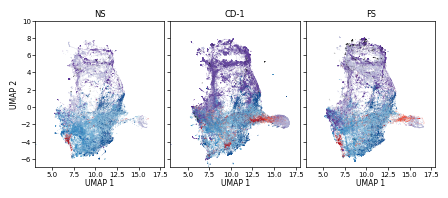

In [98]:
# --- the group maps, laid out exactly like the cluster overview (run the overview cell first) ---
BY_GROUP_DPI = 300
BY_GROUP_TITLE_FONT = OV_TITLE_FONT      # same text sizes as the overview
BY_GROUP_LABEL_FONT = OV_LABEL_FONT
BY_GROUP_TICK_FONT = OV_TICK_FONT
BY_GROUP_POINT_SIZE = OV_POINT_SIZE


def plot_umap_by_behavior_by_group(meta, embedding, ordered_behaviors, colors, titles=None):
    groups = sorted(meta["group"].unique())
    cmap = ListedColormap(colors)
    codes = pd.Categorical(meta["behavior"], categories=ordered_behaviors).codes  # -1 for unannotated frames

    # same figure size, margins, gap and map size as the overview, so the maps line up when stacked
    fig = plt.figure(figsize=OVERVIEW_FIGSIZE)
    fig_w, fig_h = OVERVIEW_FIGSIZE
    axes = [fig.add_axes([(OV_MARGIN_LEFT + k * (panel_w + OV_GAP)) / fig_w, OV_MARGIN_BOTTOM / fig_h,
                          panel_w / fig_w, panel_h / fig_h]) for k in range(len(groups))]
    for k, (ax, group) in enumerate(zip(axes, groups)):
        mask = (meta["group"] == group).to_numpy()
        group_codes = codes[mask]
        group_embedding = embedding[mask]

        unannotated = group_codes < 0
        if unannotated.any():
            ax.scatter(group_embedding[unannotated, 0], group_embedding[unannotated, 1],
                       color="0.9", s=BY_GROUP_POINT_SIZE, alpha=0.3, linewidths=0, rasterized=True)

        annotated = ~unannotated
        order = np.random.default_rng(0).permutation(annotated.sum())  # shuffle draw order across behaviors
        ax.scatter(group_embedding[annotated, 0][order], group_embedding[annotated, 1][order],
                   c=group_codes[annotated][order], cmap=cmap, vmin=0, vmax=len(ordered_behaviors) - 1,
                   s=BY_GROUP_POINT_SIZE, alpha=0.6, linewidths=0, rasterized=True)
        ax.set_xlim(map_xlim); ax.set_ylim(map_ylim)
        ax.set_xlabel("UMAP 1", labelpad=1)
        ax.tick_params(pad=1)
        if k == 0:
            ax.set_ylabel("UMAP 2", labelpad=1)
        else:
            ax.tick_params(labelleft=False)   # same y scale as the first map
        ax.set_title(titles[k] if titles else GROUP_LABELS.get(group, group), pad=3)
    return fig


with plt.rc_context({"axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2, "ytick.major.size": 2,
                     "xtick.labelsize": BY_GROUP_TICK_FONT, "ytick.labelsize": BY_GROUP_TICK_FONT,
                     "axes.labelsize": BY_GROUP_LABEL_FONT, "axes.titlesize": BY_GROUP_TITLE_FONT}):
    fig = plot_umap_by_behavior_by_group(meta, embedding, ordered_behaviors, behavior_colors)
    fig.savefig(FIG_DIR / "color_coded_umaps_by_group.png", dpi=BY_GROUP_DPI,transparent=True)   # no bbox_inches="tight": keeps the overview's exact size
    plt.show()

## Cluster × feature heatmap

Mean z-scored value of each of the 33 features in each cluster, with rows ordered by similarity (near-identical rows = two clusters with the same feature profile). The next cell reloads each frame's features from `data/features_export/`, exactly as that UMAP run prepared them, and checks the rows line up with `meta`.

In [99]:
from run_umap import UMAPConfig, load_features, prepare_data
from export_features_csv import FEATURE_NAMES

# the run's own (drop_unannotated, zscore, num_samples, random_seed) reproduce
# its exact rows in its exact order; features_dir is left at this machine's
# default rather than the path saved in config.json (e.g. the server's)
with open(RESULTS_DIR / "config.json") as f:
    saved_config = json.load(f)
raw_cfg = UMAPConfig(drop_unannotated=saved_config["drop_unannotated"], zscore=saved_config["zscore"],
                     num_samples=saved_config["num_samples"], random_seed=saved_config["random_seed"])
df_raw = load_features(raw_cfg)
# keep only the trials this run used (feature files added since the run, e.g. new animals, are
# left out before z-scoring, so the z-scores match the run's own)
df_raw = df_raw[df_raw["trial"].isin(meta["trial"].unique())]
data_raw, meta_check = prepare_data(df_raw, raw_cfg)

# line the reloaded rows up with the run's rows by (trial, frame), so the order
# the group folders were loaded in (the order of GROUPS) doesn't matter
assert len(data_raw) == len(meta), f"row count mismatch: reloaded {len(data_raw)}, meta has {len(meta)}"
reloaded_row = pd.Series(np.arange(len(meta_check)), index=pd.MultiIndex.from_frame(meta_check[["trial", "frame"]]))
assert reloaded_row.index.is_unique, "a (trial, frame) pair appears twice in the reloaded features"
row_order = reloaded_row.reindex(pd.MultiIndex.from_frame(meta[["trial", "frame"]])).to_numpy()
assert not np.isnan(row_order).any(), "some frames of this run are not in the reloaded features -- different feature files?"
row_order = row_order.astype(int)
data_raw, meta_check = data_raw[row_order], meta_check.iloc[row_order].reset_index(drop=True)
assert (meta_check["trial"].to_numpy() == meta["trial"].to_numpy()).all() and \
       (meta_check["frame"].to_numpy() == meta["frame"].to_numpy()).all(), "rows could not be aligned to this run"
print(f"reloaded {data_raw.shape[0]} x {data_raw.shape[1]} feature matrix, aligned to meta")

reloaded 211080 x 33 feature matrix, aligned to meta


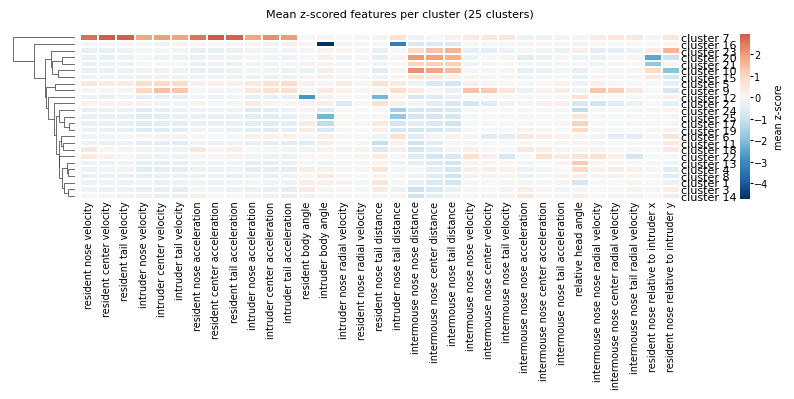

figure 8.0 x 4.0 in, cells 0.18 x 0.07 in; closest cluster pair: cluster 17 <-> cluster 19 (distance 0.90, vs. median pairwise distance 3.90)


In [100]:
from scipy.spatial.distance import pdist, squareform

HEATMAP_SAVE_PATH = FIG_DIR / "cluster_feature_heatmap.png"   # set to None to skip saving (.pdf keeps text sharp)
HEATMAP_DPI = 300
FEATURE_FONT = 7          # feature names (columns)
CLUSTER_FONT = 8          # cluster labels (rows)
CBAR_FONT = 7
HEATMAP_FIGSIZE = (8, 4)  # inches, final saved size; the heatmap cells fill what the labels leave
READABLE_NAMES = True     # "resident_nose_velocity" -> "resident nose velocity"

cluster_means = pd.DataFrame(
    [data_raw[chosen_point_clusters == c].mean(axis=0) for c in cluster_ids],
    index=[f"cluster {c}" for c in cluster_ids],
    columns=[n.replace("_", " ") if READABLE_NAMES else n for n in FEATURE_NAMES],
)

# fixed room (inches) for the dendrogram on the left, the cluster labels +
# colorbar on the right, and the long feature names below; the heatmap gets the rest
fig_w, fig_h = HEATMAP_FIGSIZE
left_room, row_label_room, cbar_room, label_room, top_room = 0.8, 0.6, 0.6, 2.0, 0.35
heat_w = fig_w - left_room - row_label_room - cbar_room
heat_h = fig_h - label_room - top_room

g = sns.clustermap(
    cluster_means, cmap="RdBu_r", center=0, row_cluster=True, col_cluster=False,
    method="average", metric="euclidean", figsize=(fig_w, fig_h),
    xticklabels=True, yticklabels=True, linewidths=0.3, linecolor="white",
    dendrogram_ratio=(0.6 / fig_w, 0.01), cbar_kws={"label": "mean z-score"},
)
# place the heatmap, dendrogram and colorbar at fixed sizes (inches), so the
# feature names always have room
g.ax_heatmap.set_position([left_room / fig_w, label_room / fig_h, heat_w / fig_w, heat_h / fig_h])
g.ax_row_dendrogram.set_position([0.1 / fig_w, label_room / fig_h, (left_room - 0.15) / fig_w, heat_h / fig_h])
g.ax_col_dendrogram.set_visible(False)
g.ax_cbar.set_position([(left_room + heat_w + row_label_room) / fig_w, label_room / fig_h, 0.1 / fig_w, heat_h / fig_h])  # past the cluster labels

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=90, fontsize=FEATURE_FONT)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=CLUSTER_FONT)
g.ax_heatmap.tick_params(length=0, pad=1)
g.ax_heatmap.set_xlabel(""); g.ax_heatmap.set_ylabel("")
g.ax_cbar.tick_params(labelsize=CBAR_FONT, length=2, pad=1)
g.ax_cbar.set_ylabel("mean z-score", fontsize=CBAR_FONT)
g.fig.suptitle(f"Mean z-scored features per cluster ({CHOSEN.num_clusters} clusters)",
               fontsize=CLUSTER_FONT, y=1 - 0.1 / fig_h, va="top")

if HEATMAP_SAVE_PATH:
    g.fig.savefig(HEATMAP_SAVE_PATH, dpi=HEATMAP_DPI)
plt.show()

# the closest pair of cluster rows in feature space -- small relative to the
# typical distance means two clusters have nearly the same feature profile
dists = squareform(pdist(cluster_means.to_numpy(), metric="euclidean"))
np.fill_diagonal(dists, np.inf)
i, j = np.unravel_index(np.argmin(dists), dists.shape)
print(f"figure {fig_w:.1f} x {fig_h:.1f} in, cells {heat_w / cluster_means.shape[1]:.2f} x {heat_h / cluster_means.shape[0]:.2f} in; closest cluster pair: {cluster_means.index[i]} <-> {cluster_means.index[j]} "
      f"(distance {dists[i, j]:.2f}, vs. median pairwise distance {np.median(dists[np.isfinite(dists)]):.2f})")

# Proportion of cluster in each behavior

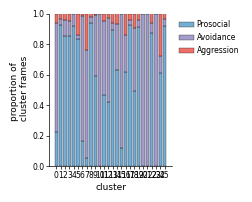

family   Prosocial  Avoidance  Aggression      n
cluster                                         
0             0.23       0.71        0.06   2030
1             0.92       0.04        0.04  14025
2             0.85       0.11        0.04  13008
3             0.85       0.10        0.05  15170
4             0.92       0.08        0.00   5622
5             0.83       0.03        0.14  10821
6             0.16       0.82        0.02  12382
7             0.06       0.70        0.24  11906
8             0.94       0.04        0.02   5108
9             0.59       0.40        0.01  10727
10            0.00       1.00        0.00  11782
11            0.46       0.49        0.05   6443
12            0.42       0.55        0.03   4788
13            0.89       0.05        0.06   6433
14            0.63       0.30        0.07   4870
15            0.12       0.88        0.00  11384
16            0.62       0.24        0.14   1753
17            0.93       0.03        0.05   6356
18            0.49  

In [101]:
from umap_clusters import BEHAVIOR_FAMILY

FIGSIZE = (2.5,2)       # inches
FONT_SIZES = {
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
    "legend.fontsize": 5.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}
SHARE_FAMILIES = ["Prosocial", "Avoidance", "Aggression"]   # blue, purple, red
family_colors = {family: plt.get_cmap(FAMILY_CMAP_NAME[family])(0.65) for family in SHARE_FAMILIES}

# one row per frame: its cluster and its behavior family (unannotated / other families dropped)
frame_families = pd.DataFrame({"cluster": chosen_point_clusters, "family": meta["behavior"].map(BEHAVIOR_FAMILY)})
frame_families = frame_families[frame_families["family"].isin(SHARE_FAMILIES)]

# share of each cluster's annotated frames that come from each family (each bar sums to 1)
cluster_family_share = (pd.crosstab(frame_families["cluster"], frame_families["family"], normalize="index")
                        .reindex(columns=SHARE_FAMILIES, fill_value=0))
cluster_family_n = frame_families["cluster"].value_counts().sort_index()

with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    bottom = np.zeros(len(cluster_family_share))
    x = np.arange(len(cluster_family_share))
    for family in SHARE_FAMILIES:
        ax.bar(x, cluster_family_share[family], bottom=bottom, width=0.75, color=family_colors[family],
               edgecolor="k", linewidth=0.3, alpha=.7, label=family)
        bottom += cluster_family_share[family].to_numpy()
    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}" for c in cluster_family_share.index])
    ax.set_xlabel("cluster"); ax.set_ylabel("proportion of \n cluster frames")
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), handletextpad=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "cluster_family_share.png", dpi=300, transparent=True)
    plt.show()

print(cluster_family_share.round(2).assign(n=cluster_family_n).to_string())